# Project 26: Analisis compliance

Q4–Q13. Putusan lolos/gagal dihitung dengan aturan pasti di SQL (ASOF join ke revisi spec yang berlaku pada tanggal uji). Data adalah simulasi buatan sendiri.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## Q4. Pass rate per parameter dan model (interval Wilson 95%)

In [2]:
w = R('wilson_passrate.csv'); w

,parameter,model,n_pass,n,pass_rate,ci_low,ci_high,n_enough
0,cct,12W,4474,4474,1.0000,0.9991,1.0000,True
1,cct,5W,6062,6063,0.9998,0.9991,1.0000,True
2,cct,9W,7107,7112,0.9993,0.9984,0.9997,True
3,cri,12W,4390,4483,0.9793,0.9747,0.9830,True
4,cri,5W,6038,6048,0.9983,0.9970,0.9991,True
5,cri,9W,7088,7101,0.9982,0.9969,0.9989,True
6,efficacy,12W,4476,4478,0.9996,0.9984,0.9999,True
7,efficacy,5W,6059,6060,0.9998,0.9991,1.0000,True
8,efficacy,9W,7125,7125,1.0000,0.9995,1.0000,True
9,luminous_flux,12W,4465,4469,0.9991,0.9977,0.9997,True


## Q5. Pareto kegagalan

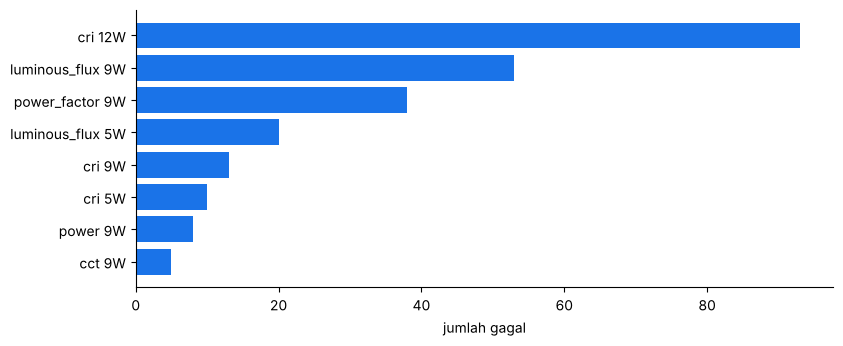

In [3]:
p = R('pareto_fail.csv').head(8); plt.barh(p.parameter + ' ' + p.model, p.n_fail, color=BLUE); plt.gca().invert_yaxis(); plt.xlabel('jumlah gagal'); plt.show()

## Q6. Margin ke batas spec (dalam simpangan baku) dan hasil hampir gagal

In [4]:
display(R('margin_param_model.csv')); R('near_fail_sensitivity.csv').pivot_table(index='near_fail_sd', values='n_near_fail', aggfunc='sum')

,parameter,model,n,median_margin_sd,p05_margin_sd,min_margin_sd,median_margin_pct,p05_margin_pct,n_near_fail,share_near_fail,pass_rate
0,cri,12W,4483,2.0098,0.3350,-1.4515,0.0225,0.0037,553.0000,0.1234,0.9793
1,power_factor,9W,7123,2.4599,0.7380,-1.7220,0.2000,0.0600,563.0000,0.0790,0.9947
2,luminous_flux,9W,7114,2.7202,0.8444,-1.4559,0.0724,0.0223,423.0000,0.0595,0.9925
3,luminous_flux,5W,6022,2.8541,1.1916,-0.7706,0.1000,0.0417,187.0000,0.0311,0.9967
4,cri,5W,6048,2.8691,1.2194,-0.6456,0.0500,0.0213,158.0000,0.0261,0.9983
5,cri,9W,7101,2.8996,1.2323,-0.6524,0.0500,0.0213,183.0000,0.0258,0.9982
6,power_factor,5W,6054,2.9756,1.2398,-0.4959,0.2400,0.1000,202.0000,0.0334,0.9993
7,power,9W,7144,2.9942,1.3474,-0.6986,0.0632,0.0284,170.0000,0.0238,0.9989
8,power,12W,4502,3.1473,1.4950,-0.3934,0.0640,0.0304,79.0000,0.0175,0.9998
9,cct,9W,7112,3.1550,1.8825,-0.2945,0.0629,0.0371,30.0000,0.0042,0.9993


,n_near_fail
near_fail_sd,
0.5000,826.0000
1.0000,2838.0000
2.0000,16544.0000


## Q7. Tren bulanan

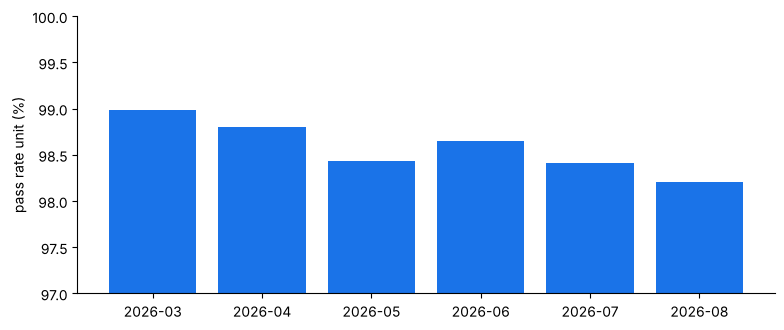

,test,months,z,p_value,first_month_rate,last_month_rate
0,Cochran-Armitage,6,-2.6902,0.0071,0.9899,0.9821


In [5]:
m = R('month_unit.csv'); plt.bar(m.month, m.pass_rate * 100, color=BLUE); plt.ylim(97, 100); plt.ylabel('pass rate unit (%)'); plt.show(); R('trend_month.csv')

## Q8. Dampak revisi spec yang salah

In [6]:
display(R('revision_param_model.csv').query("model == '9W' and parameter == 'luminous_flux'")); R('impact_stale_spec.csv')

,model,parameter,revision,n,n_pass,pass_rate
45,9W,luminous_flux,Rev 1.0,2436,2436.0000,1.0000
46,9W,luminous_flux,Rev 2.0,2374,2346.0000,0.9882
47,9W,luminous_flux,Rev 3.0,2304,2279.0000,0.9891


,stale_revision,n_units,units_truly_fail,units_fail_hidden,units_false_alarm,rows_truly_fail,rows_fail_hidden,share_fail_hidden_units,share_fail_hidden_rows
0,Rev 1.0,18000,254.0000,54.0000,0.0000,255.0000,54.0000,0.2126,0.2118
1,Rev 2.0,18000,254.0000,3.0000,28.0000,255.0000,3.0000,0.0118,0.0118


## Q9. Waktu pengecekan manual (estimated)

In [7]:
R('impact_manual_time.csv')

,minutes_per_doc,docs_in_data,hours_in_data_period,hours_per_year,basis
0,10,24,4.0000,8.0000,asumsi menit/dokumen; data sekitar 6 bulan x2
1,20,24,8.0000,16.0000,asumsi menit/dokumen; data sekitar 6 bulan x2
2,30,24,12.0000,24.0000,asumsi menit/dokumen; data sekitar 6 bulan x2


## Q10. Unit gagal yang tampak lolos (proxy: spec usang)
Tidak ada data cek manual pada lot; proksinya adalah penilaian dengan revisi lama.

In [8]:
R('impact_stale_spec.csv')[['stale_revision', 'units_truly_fail', 'units_fail_hidden', 'share_fail_hidden_units']]

,stale_revision,units_truly_fail,units_fail_hidden,share_fail_hidden_units
0,Rev 1.0,254.0000,54.0000,0.2126
1,Rev 2.0,254.0000,3.0000,0.0118


## Q11. Validasi: SQL vs pandas vs Excel vs kunci jawaban simulasi, dan lima fakta yang ditanam

In [9]:
print(R('pandas_crosscheck.csv').to_string()); b = R('crosscheck_excel.csv'); print(f'Excel: {(b.status == "PASS").sum()} dari {len(b)} PASS'); display(R('truth_compliance_check.csv')); R('ground_truth_check.csv')

           check    rows  result_mismatch  revision_mismatch
0  SQL vs pandas  105939                0                  0
Excel: 54 dari 54 PASS


,rows_checked,missing_truth,result_mismatch,revision_mismatch,truth_fail,pipeline_fail
0,105939,0,0,0,255,255


,fact_no,fakta,ditemukan,hasil
0,1,CRI pada model 12W paling dekat ke batas,median margin CRI 12W 2.01 simpangan baku (5W ...,Sesuai
1,2,Revisi spec menaikkan batas minimal luminous f...,batas 800 lm (Rev 1.0) menjadi 830 lm (Rev 2.0...,Sesuai
2,3,Satuan dan simbol beragam antar format,aturan dasar gagal pada 58 field kalimat dan 1...,Sesuai
3,4,Tabel terpotong dan satu PDF hasil scan,12 field gagal pada tabel terpotong; PDF scan ...,Sesuai
4,5,Sekitar 2–3% hasil ukur kotor,2700 dari 108540 baris (2.49%); semua jenis di...,Sesuai


## Q13. Kualitas data hasil ukur

In [10]:
display(R('cleaning_log.csv')); display(R('data_quality_summary.csv')); R('dirty_found_vs_planted.csv')

,rule,description,table,rows_found,rows_dropped,rows_fixed,decision
0,R1,"Baris ganda (unit_id dan parameter sama, isi i...",measurement,540,540,0,Dibuang; baris pertama dipertahankan
1,R2,Nilai kosong,measurement,981,981,0,Dibuang; tidak ada dasar untuk menebak nilai
2,R3,Nilai berupa teks N/A,measurement,540,540,0,Dibuang
3,R4,Nilai sentinel -999,measurement,540,540,0,Dibuang
4,R5,Power dalam mW (nilai 1.000 kali lebih besar),measurement,99,0,99,Dikonversi ke W (dibagi 1.000)
5,R6,Satuan tidak sesuai kamus parameter (selain mW...,measurement,0,0,0,Dibuang


,table,raw_rows,clean_rows,bad_rows,bad_pct,dropped,fixed
0,measurement,108540,105939,2700,2.4876,2601,99


,issue,description,planted,found,match
0,duplicate,Baris ganda,540,540,True
1,blank,Nilai kosong (termasuk kolom satuan salah yang...,981,981,True
2,text_na,Teks N/A,540,540,True
3,sentinel,Sentinel -999,540,540,True
4,mW,Power dalam mW,99,99,True


## Beda antar model (chi-square, koreksi Holm)

In [11]:
R('chi2_models.csv')

,parameter,chi2,dof,p_value,min_expected,cramers_v,p_holm,significant_holm_0_05
0,cri,184.5970,2,0.0000,29.4934,0.1023,0.0000,True
1,power_factor,44.4623,2,0.0000,10.6635,0.0502,0.0000,True
2,luminous_flux,29.4122,2,0.0000,19.5463,0.0409,0.0000,True
3,power,4.8596,2,0.0881,2.7933,0.0166,0.2642,False
4,cct,4.8267,2,0.0895,1.5210,0.0165,0.2642,False
5,efficacy,3.2313,2,0.1988,0.7606,0.0135,0.2642,False
